In [35]:
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

In [36]:
class Point:
    x = None
    y = None

    def __init__(self,coor_x,coor_y):
        self.x=coor_x
        self.y=coor_y

    def __lt__(self, other):
      if(self.x != other.x):
        return self.x < other.x
      return self.y < other.y
    
    def plot(self, tag='', color=''): 
        kwargs = {} # A modification of the original class, allows passing independent arguments
        if color:
            kwargs['c'] = color
        if tag:
            kwargs['label'] = tag

        plt.scatter(self.x, self.y, **kwargs)
            
        if tag:
            plt.legend()
            
    def __repr__(self):
      return f"({self.x}, {self.y})"

    

In [37]:
class Segment:
    start = None
    end = None
    angle = None
    half = None

    def __init__(self, A, B ):
        if A < B:
            self.start = A
            self.end = B
        else:
            self.start = B
            self.end = A
    
        self.angle = self.calcAngle()
        self.half  = self.calcHalf()
        
    def __repr__(self):
      return f"[{self.start}, {self.end}]"

    def plot(self, tag='', color=''):
        kwargs = {} 
        if color:
            kwargs['c'] = color
        if tag:
            kwargs['label'] = tag

        segmento = [ [self.start.x, self.start.y ],  [self.end.x, self.end.y ] ]

        self.start.plot(**kwargs)
        self.end.plot(**kwargs)
        if color:
            plt.plot( [s[0] for s in segmento], [s[1] for s in segmento] ,  linestyle="-", color =color)
        else:
            plt.plot( [s[0] for s in segmento], [s[1] for s in segmento] ,  linestyle="-")

    def calcHalf(self):
        x = None
        y = None
        if(self.start.x == self.end.x):
            x = self.start.x
        else:
            x = self.start.x + abs(self.start.x-self.end.x)/2

        if(self.start.y == self.end.y):
            y = self.start.y
        else:
            if(self.start.y > self.end.y):
                y = self.end.y + abs(self.start.y-self.end.y)/2
            else:
                y = self.start.y + abs(self.start.y-self.end.y)/2
        
        print(f"start: {self.start}, end: {self.end}, half: ({x},{y})")
        return Point(x, y)


    def calcAngle(self):
        if(self.start.y == self.end.y): #Division by 0
            return 0
        if(self.start.x == self.end.x): # 90 degrees
            return float('inf')

        M = (self.start.x-self.end.x) / (self.start.y-self.end.y)
        return 
        


In [38]:
class Triangle:
    circumcenter = None
    circumradius = None


    def __init__(self,p1, p2,p3):

        self.points = []
        self.segments = []

        self.p1 = self.points.append(p1)
        self.p2 = self.points.append(p2)
        self.p3 = self.points.append(p3)
        self.segments.append(Segment(p1,p2))
        self.segments.append(Segment(p2,p3))
        self.segments.append(Segment(p3,p1))
        self.circumcenter, self.circumradius = self.calculateCircumcenter()


    def plot(self,ax):
        for p in self.points:
            p.plot()

        triangle_coords = [(p.x,p.y) for p in self.points]
        triangle = Polygon(triangle_coords, closed=True, facecolor='lightblue', edgecolor='darkgreen', alpha=0.6)
        ax.add_patch(triangle)
        
        self.circumcenter.plot(tag='Circumcenter', color='red') 
        circle = plt.Circle((self.circumcenter.x, self.circumcenter.y), self.circumradius, color='lightblue', fill=False, linestyle='-', linewidth=1)
        ax.add_patch(circle)

    def calculateCircumcenter(self):
        A = self.points[0]
        B = self.points[1]
        C = self.points[2]

        D = 2 * (A.x * (B.y - C.y) + B.x * (C.y - A.y) + C.x * (A.y - B.y))
        if D == 0:
            return None  # The points are collinear, circumcenter is undefined

        Ux = ((A.x**2 + A.y**2) * (B.y - C.y) + (B.x**2 + B.y**2) * (C.y - A.y) + (C.x**2 + C.y**2) * (A.y - B.y)) / D
        Uy = ((A.x**2 + A.y**2) * (C.x - B.x) + (B.x**2 + B.y**2) * (A.x - C.x) + (C.x**2 + C.y**2) * (B.x - A.x)) / D
        
        radio = math.sqrt((Ux - A.x)**2 + (Uy - A.y)**2)

        return Point(Ux, Uy), radio
    

In [ ]:
def calculateSuperTriangle(points):
    y_min = float('inf')
    y_max = float('-inf')
    x_min = float('inf')
    x_max = float('-inf')

    for p in points:
        y_min = min(p.y, y_min)
        y_max = max(p.y, y_max)
        x_min = min(p.x, x_min)
        x_max = max(p.x, x_max)

    x_len = abs(x_max - x_min)
    y_len = abs(y_max - y_min)

    if y_min == y_max or x_min == x_max or len(points) == 0:
        print("La figura forma una línea o está vacía")
        return

    # We draw a square using this maxes
    upper_left = Point(x_min, y_max)
    upper_right = Point(x_max, y_max)
    lower_right = Point(x_max, y_min)
    lower_left = Point(x_min, y_min)

    # We create a triangle, the upper point is in the middle of the upper edge of the rectangle, plus the 
    middle_point = Point(x_min+(x_max-x_min)/2, y_max+(y_len+x_len)/2)
    # f(x) = mx+b  -> y = mx+b
    m = (upper_left.y-middle_point.y)/(upper_left.x-middle_point.x)

    # b = y -mx
    b1 = upper_left.y - m * upper_left.x
    b2 = upper_right.y - (-m) * upper_right.x

    # x = (y-b)/m
    left_point = Point((y_min-b1)/m, y_min)
    right_point = Point((y_min-b2)/(-m), y_min)

    middle_point.plot()
    left_point.plot()
    right_point.plot()

    plt.axhline(y=y_min, color='b', linestyle='--', label='ymin')
    plt.axhline(y=y_max, color='b', linestyle='--', label='ymax')
    plt.axvline(x=x_min, color='b', linestyle='--', label='xmin')
    plt.axvline(x=x_max, color='b', linestyle='--', label='xmax')

    plt.axvline(x=x_min+(x_max-x_min)/2, color='b', linestyle='--', label='xmax')

    triangle_points = [left_point,middle_point,right_point]
    triangle_coords=[(p.x,p.y) for p in triangle_points]
    triangle = Polygon(triangle_coords, closed=True, facecolor='lightgreen', edgecolor='darkgreen', alpha=0.3)

    rectangle_points = [upper_left, upper_right , lower_right, lower_left]
    rectangle_coords = [(p.x,p.y) for p in rectangle_points]
    rectangle = Polygon(rectangle_coords, closed=True, facecolor='lightblue', edgecolor='darkgreen', alpha=0.6)


    ax.add_patch(triangle)
    ax.add_patch(rectangle)

    for p in points:
        p.plot()



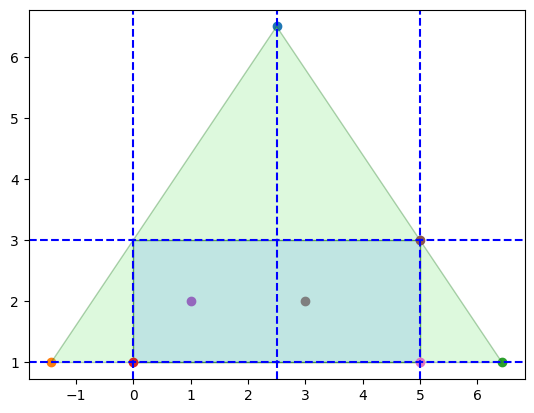

In [40]:
coordinates = [[0,1],[1,2],[5,3],[5,1],[3,2]]
fig, ax = plt.subplots()
points = [ Point(x[0],x[1]) for x in coordinates]
calculateSuperTriangle(points)

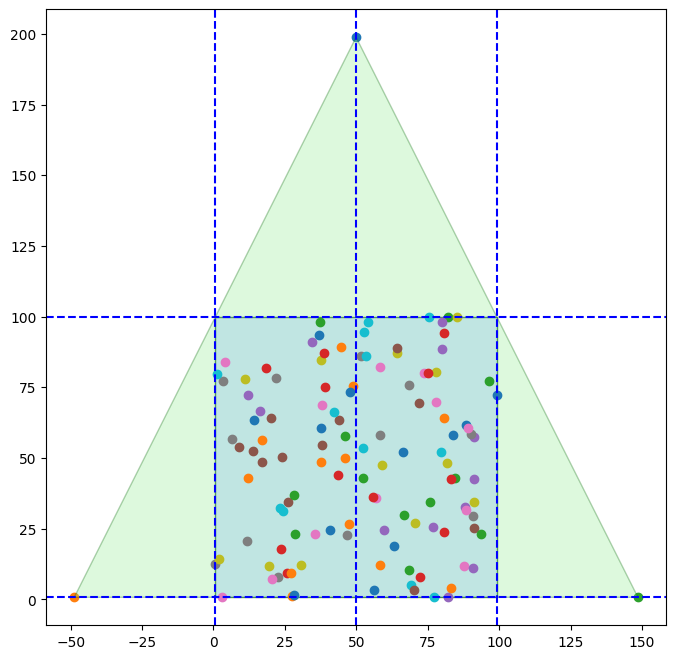

In [41]:
import random

# Arreglo reproducible de 120 puntos aleatorios dentro de un cuadrado de 100 x 100
random.seed(random.seed(10))
coordinates_large = [
    [random.uniform(0, 100), random.uniform(0, 100)]
    for _ in range(120)
]
points_large = [Point(x, y) for x, y in coordinates_large]

fig, ax = plt.subplots(figsize=(8, 8))
calculateSuperTriangle(points_large)
